# Aula 05 · Vídeo 2 — GDPR e EU AI Act para LLMs e Foundation Models

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs · **Caso condutor:** Banco **Aurora** / **Aurora Assist**
> **Tipo:** conceitual **+** prático · **Doc 04:** seções 5 (GDPR), 6-7 (EU AI Act, pirâmide de risco, R = Σ Pj·Ij)

## 🎯 Objetivos
- Traduzir **GDPR** (art. 22 decisão automatizada, art. 25 Privacy by Design, art. 35 DPIA) em requisitos de engenharia.
- Classificar o Aurora Assist na **pirâmide de risco do EU AI Act** e ver como *informar* vs *decidir crédito* muda o fardo regulatório.
- Calcular o **risco agregado** $R = \sum_j P_j \cdot I_j$ e decidir sobre mitigações.

> [!WARNING]
> ⚠️ **Uso ético.** Todos os dados são sintéticos; o objetivo é **defensivo e didático** (Doc 04).

## 1. Teoria (Doc 04, §5) — o padrão europeu

> *"Um sistema desenhado para ser conforme com a LGPD já cobre a maior parte das exigências do GDPR, pois as duas leis compartilham a mesma filosofia."* — Doc 04, §5

Três artigos do **GDPR** importam para quem constrói LLMs: **art. 22** (restringe decisões *unicamente* automatizadas com efeito significativo), **art. 25** (*Privacy by Design and by Default*) e **art. 35** (**DPIA** para alto risco).

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print('ROOT =', ROOT)

ROOT = /Users/miyake-san/Projects/9mlet-llm-security/aula05_conformidade_lgpd_gdpr


In [2]:
from src.security.regulations import (
    LEGAL_BASIS_GDPR_MAP, FRAMEWORK_CROSSWALK, MAX_FINES,
)
from src.security.schemas import LegalBasis

print('Correspondência de base legal LGPD -> GDPR:')
for basis, gdpr in LEGAL_BASIS_GDPR_MAP.items():
    print(f'  {basis.value:22s} -> {gdpr}')

print('\nMultas máximas:')
for law, fine in MAX_FINES.items():
    print(f'  {law.upper():8s}: {fine}')

Correspondência de base legal LGPD -> GDPR:
  consentimento          -> GDPR art. 6(1)(a) — consent
  execucao_contrato      -> GDPR art. 6(1)(b) — contract
  obrigacao_legal        -> GDPR art. 6(1)(c) — legal obligation
  protecao_da_vida       -> GDPR art. 6(1)(d) — vital interests
  politica_publica       -> GDPR art. 6(1)(e) — public task
  legitimo_interesse     -> GDPR art. 6(1)(f) — legitimate interests
  protecao_ao_credito    -> (sem equivalente direto no GDPR)

Multas máximas:
  LGPD    : 2% do faturamento, limitado a R$ 50 milhões por infração (art. 52).
  GDPR    : até 4% do faturamento global anual (art. 83).
  EU_AI_ACT: até 7% do faturamento global para práticas proibidas.


In [3]:
# Mapeamento cruzado de obrigações entre frameworks (Doc 04, §8).
print('Obrigação                | LGPD        | GDPR        | EU AI Act')
print('-' * 78)
for obligation, m in FRAMEWORK_CROSSWALK.items():
    print(f"{obligation:24s} | {m['lgpd']:11s} | {m['gdpr']:11s} | {m['eu_ai_act']}")

Obrigação                | LGPD        | GDPR        | EU AI Act
------------------------------------------------------------------------------
registro_de_tratamento   | art. 37     | art. 30     | logs automáticos (alto risco)
avaliacao_de_impacto     | RIPD (art. 38) | DPIA (art. 35) | sistema de gestão de risco
privacy_by_design        | art. 46 (segurança) | art. 25     | data governance
decisao_automatizada     | art. 20     | art. 22     | supervisão humana
transparencia            | art. 6, VI  | arts. 13-14 | art. 50 (informar que é IA)


## 2. Teoria (Doc 04, §6) — EU AI Act: regulação por nível de risco

O **EU AI Act** (Regulation EU 2024/1689) regula o *sistema de IA* por uma **pirâmide de risco**: **inaceitável** (proibido), **alto** (crédito, saúde, recrutamento — requisitos rigorosos), **limitado** (chatbots — transparência) e **mínimo** (uso livre).

> *"As escolhas de produto definem o fardo regulatório."* — Doc 04, §6

In [4]:
from src.security.dpia import classify_ai_system

# Aurora Assist no cenário-base: apenas INFORMA (Doc 04, §7).
tier_info, obl_info, why_info = classify_ai_system(
    ['conversational', 'informational_assistant', 'balance_inquiry']
)
print('Aurora Assist (informativo):')
print('  nível     :', tier_info.value)
print('  obrigações:', ', '.join(obl_info))
print('  motivo    :', why_info)

Aurora Assist (informativo):
  nível     : limited
  obrigações: transparencia_ao_usuario, documentacao_minima
  motivo    : Art. 50: interação direta com pessoas exige transparência.


In [5]:
# E se o banco usar o assistente para DECIDIR crédito? Migra para ALTO RISCO.
tier_credit, obl_credit, why_credit = classify_ai_system(
    ['conversational', 'credit_decision']
)
print('Aurora Assist (decisão de crédito):')
print('  nível     :', tier_credit.value)
print('  obrigações:', ', '.join(obl_credit))
print('  motivo    :', why_credit)

delta = set(obl_credit) - set(obl_info)
print(f'\nObrigações ADICIONAIS ao virar alto risco ({len(delta)}):')
for ob in sorted(delta):
    print('  +', ob)

Aurora Assist (decisão de crédito):
  nível     : high
  obrigações: sistema_gestao_de_risco, documentacao_tecnica_extensa, supervisao_humana_significativa, registro_automatico_de_logs, avaliacao_de_conformidade, dpia_obrigatoria
  motivo    : Anexo III: sistemas que decidem acesso a serviços essenciais.

Obrigações ADICIONAIS ao virar alto risco (6):
  + avaliacao_de_conformidade
  + documentacao_tecnica_extensa
  + dpia_obrigatoria
  + registro_automatico_de_logs
  + sistema_gestao_de_risco
  + supervisao_humana_significativa


## 3. Árvore de decisão visual — informar vs decidir

A fronteira entre **informar** e **decidir** é, ao mesmo tempo, técnica e jurídica. Desenhar o assistente para *informar* e deixar a *decisão* de crédito para um humano supervisionado reduz drasticamente a complexidade de conformidade (Doc 04, §7).

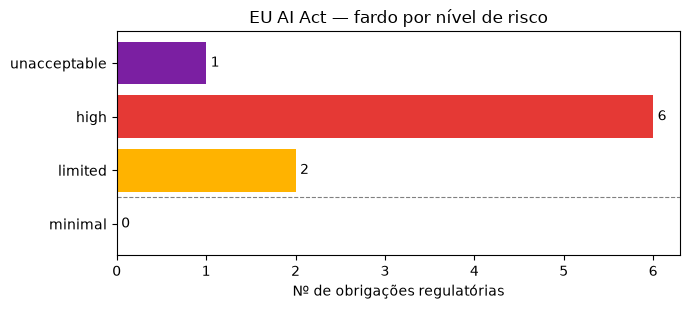

Aurora Assist informativo => limited (fardo mínimo de transparência).


In [6]:
import matplotlib.pyplot as plt

tiers = ['minimal', 'limited', 'high', 'unacceptable']
from src.security.regulations import AI_ACT_OBLIGATIONS
from src.security.schemas import RiskTier

counts = [len(AI_ACT_OBLIGATIONS[RiskTier(t)]) for t in tiers]
colors = ['#4caf50', '#ffb300', '#e53935', '#7b1fa2']

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(tiers, counts, color=colors)
ax.set_xlabel('Nº de obrigações regulatórias')
ax.set_title('EU AI Act — fardo por nível de risco')
for i, c in enumerate(counts):
    ax.text(c + 0.05, i, str(c), va='center')
ax.axhline(0.5, color='gray', ls='--', lw=0.8)
plt.tight_layout(); plt.show()
print('Aurora Assist informativo =>', tier_info.value, '(fardo mínimo de transparência).')

## 4. Teoria (Doc 04, §7) — cálculo de risco da DPIA

Formalizamos o risco agregado de um tratamento como a soma, sobre os cenários $j$, do produto entre a probabilidade $P_j$ e o impacto $I_j$ (ponderado por gravidade jurídica e reputacional):

$$
R_{\text{tratamento}} = \sum_{j} P_j \cdot I_j
$$

Cenários de alto $P_j \cdot I_j$ exigem salvaguardas reforçadas; riscos residuais baixos são aceitos e **documentados**.

Risco agregado normalizado R = 0.1032  ->  decisão: accept


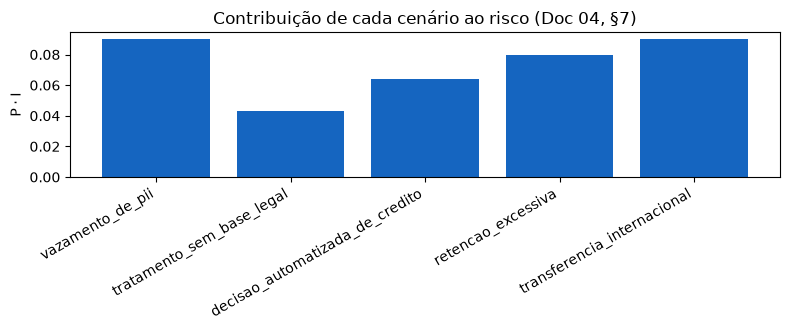

In [7]:
from src.security.dpia import aggregate_risk, decide, default_scenarios

scenarios = default_scenarios()
R = aggregate_risk(scenarios)
print(f'Risco agregado normalizado R = {R}  ->  decisão: {decide(R)}')

# Contribuição de cada cenário (P * I) — prioriza mitigações objetivamente.
from src.security.dpia import load_thresholds
weights = load_thresholds()['risk']['impact_weights']
names = [s.name for s in scenarios]
contrib = [round(s.probability * weights[s.impact.value], 3) for s in scenarios]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(names, contrib, color='#1565c0')
ax.set_ylabel('P · I')
ax.set_title('Contribuição de cada cenário ao risco (Doc 04, §7)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

## 5. Lição de arquitetura — a decisão de produto define o risco

Mantendo o Aurora Assist **informativo**, o risco agregado permanece baixo e o nível EU AI Act permanece **limitado**. Introduzir decisão automatizada de crédito eleva ambos — e obriga DPIA, supervisão humana e documentação extensa.

In [8]:
# Compara o risco quando um cenário de decisão automatizada tem P alto.
from src.security.schemas import RiskScenario, ImpactCategory

alto = default_scenarios() + [
    RiskScenario('credito_automatizado_massivo', 0.7, ImpactCategory.AUTOMATED_DECISION,
                 'Assistente decide crédito em escala sem revisão.'),
]
R_alto = aggregate_risk(alto)
print(f'R (informativo) = {R}  -> {decide(R)}')
print(f'R (com decisão automatizada P=0.7) = {R_alto}  -> {decide(R_alto)}')
print('\nConclusão: a mesma engenharia, com uma escolha de produto diferente,')
print('muda a decisão de conformidade. Informar é mais barato que decidir.')

R (informativo) = 0.1032  -> accept
R (com decisão automatizada P=0.7) = 0.213  -> mitigate

Conclusão: a mesma engenharia, com uma escolha de produto diferente,
muda a decisão de conformidade. Informar é mais barato que decidir.


## ✅ Resumo e gancho

- **GDPR** e **LGPD** compartilham filosofia; art. 22/25/35 orientam LLMs.
- A **pirâmide do EU AI Act** transforma escolhas de produto em fardo regulatório.
- $R = \sum_j P_j \cdot I_j$ prioriza mitigações de forma objetiva.

➡️ **Vídeo 3:** conduziremos uma **DPIA** completa, com **consentimento granular**, **direitos do titular** e a **purga seletiva** do direito ao esquecimento.